# 00 — GWOSC: exploration of the gravitational-wave data and of the burst waveforms

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

This notebook has a precise and limited goal: **read, visualise and understand the structure of the raw data** before building any statistical or ML pipeline.
It is the exploratory prototype of the project; the final, validated pipeline starts at notebook `01`.

Contents:
1. Access to the GWOSC data with GWpy
2. Raw H1 and L1 strain
3. PSD (power spectral density) and detector sensitivity curves
4. Whitening and band-pass filtering
5. Time–frequency representations (spectrogram, simplified Q-transform)
6. Construction and visualisation of simulated bursts (sine-Gaussian, Gaussian pulse, chirp-like)
7. Injection of a burst into real noise and visual comparison
8. SNR of an injection

> No ML, no detection statistics, no ROC curve. Only data and physics.
>
> **Note.** The SNR defined in section 7 (L2 norm of the whitened waveform over the noise standard deviation) is a time-domain proxy. From notebook `02` on, the project uses the analytic optimal SNR $\rho^2=4\int|\tilde h|^2/S_n\,df$ with the PSD of each data chunk.

## 0. Setup and dependencies

```bash
# with conda
conda install -c conda-forge gwpy gwosc numpy scipy matplotlib

# or with pip
pip install gwpy gwosc numpy scipy matplotlib
```

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.signal import butter, filtfilt, welch, spectrogram

plt.rcParams.update({
    "figure.figsize": (13, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

# Consistent colours for the two detectors
COLOR = {"H1": "#1f77b4", "L1": "#ff7f0e", "burst": "#2ca02c"}

In [2]:
# Try to import GWpy / GWOSC.
# If they are missing, the notebook falls back to realistic simulated noise.

try:
    from gwpy.timeseries import TimeSeries
    from gwosc.datasets import event_gps
    GW_AVAILABLE = True
    print("✓ GWpy and GWOSC available — using real LIGO data.")
except ImportError as e:
    GW_AVAILABLE = False
    print(f"✗ GWpy/GWOSC not available ({e}).")
    print("  The notebook will continue with realistic simulated (coloured) noise.")

✓ GWpy and GWOSC available — using real LIGO data.


## 1. GWOSC download — GW150914

GW150914 is the first event detected by LIGO (September 2015): the coalescence of two black holes of about 36 and 29 solar masses, at about 410 Mpc.
We use a **64-second** window centred on the event — long enough to see both the signal and the surrounding stationary noise.

> **Note:** in the actual project we use segments *far* from known events as background noise. Here GW150914 only serves as a visual validation of the pipeline.

In [3]:
EVENT     = "GW150914"
WINDOW    = 64      # total seconds around the event
FS_TARGET = 4096    # Hz — native LIGO sampling rate in O1

if GW_AVAILABLE:
    gps   = event_gps(EVENT)
    start = int(gps - WINDOW / 2)
    end   = int(gps + WINDOW / 2)
    print(f"Event  : {EVENT}")
    print(f"GPS    : {gps:.3f} s")
    print(f"Range  : [{start}, {end}] GPS")

    h1 = TimeSeries.fetch_open_data("H1", start, end, cache=True)
    l1 = TimeSeries.fetch_open_data("L1", start, end, cache=True)

    # Convert to numpy
    t_h1  = h1.times.value - gps
    x_h1  = np.asarray(h1.value)
    t_l1  = l1.times.value - gps
    x_l1  = np.asarray(l1.value)
    fs    = float(1.0 / h1.dt.value)

    print(f"\nH1: {len(x_h1)} samples @ {fs:.0f} Hz  |  strain range: [{x_h1.min():.2e}, {x_h1.max():.2e}]")
    print(f"L1: {len(x_l1)} samples @ {fs:.0f} Hz  |  strain range: [{x_l1.min():.2e}, {x_l1.max():.2e}]")

else:
    # ── Fallback: realistic coloured noise ────────────────────────────────────
    # Simulate an approximate LIGO PSD (1/f^2 + flat + resonances)
    # and add a GW150914-like signal.
    rng   = np.random.default_rng(42)
    fs    = float(FS_TARGET)
    gps   = 0.0
    N     = int(WINDOW * fs)
    t_h1  = np.linspace(-WINDOW/2, WINDOW/2, N, endpoint=False)
    t_l1  = t_h1.copy()

    def make_colored_noise(N, fs, seed=0):
        """Coloured noise with an approximate LIGO-like PSD."""
        rng_local = np.random.default_rng(seed)
        white = rng_local.normal(size=N)
        f     = np.fft.rfftfreq(N, d=1/fs)
        fft   = np.fft.rfft(white)
        # Colour it: S(f) ~ 1/f^2 below 100 Hz, flat above, with a bump at 60 Hz (mains line)
        psd   = np.ones_like(f)
        psd[f > 0] = (1 / (f[f > 0] / 100)**1.5 + 1.0)
        psd[np.abs(f - 60) < 1] *= 10   # 60 Hz mains line
        psd[np.abs(f - 120) < 1] *= 5
        amp   = 1e-21 * np.sqrt(psd * N / fs)
        amp[0] = 0
        colored = np.fft.irfft(fft * amp, n=N)
        return colored

    x_h1_noise = make_colored_noise(N, fs, seed=42)
    x_l1_noise = make_colored_noise(N, fs, seed=99)

    # Add an approximate GW150914-like chirp
    def gw150914_like(t, t_coal=0.0, f0=35.0, m_chirp=28.3):
        """Leading-order PN approximation of the chirp phase."""
        tau  = np.maximum(t_coal - t, 1e-4)
        G, c = 6.674e-11, 3e8
        Msun = 1.989e30
        Mc   = m_chirp * Msun
        # f_gw(tau) = (1/8pi) * (5/256)^(3/8) * (G Mc / c^3)^(-5/8) * tau^(-3/8)
        coeff = (1 / (8 * np.pi)) * (5/256)**(3/8)
        fac   = (G * Mc / c**3)**(-5/8)
        f_gw  = coeff * fac * tau**(-3/8)
        f_gw  = np.clip(f_gw, 10, 400)
        # Integrated phase
        phase = 2 * np.pi * np.cumsum(f_gw) / fs
        # Amplitude: grows towards the merger, then decays (simplified ringdown)
        amp_env = 1e-21 * (tau / 0.5)**(-1/4)
        amp_env = np.where(t < t_coal, amp_env, amp_env[np.argmin(np.abs(t - t_coal))] * np.exp(-(t - t_coal) * 50))
        return amp_env * np.sin(phase)

    sig = gw150914_like(t_h1, t_coal=0.0)
    x_h1 = x_h1_noise + sig
    x_l1 = x_l1_noise + sig * 0.85  # L1 slightly attenuated

    print("Fallback: coloured noise + GW150914-like chirp generated.")
    print(f"N = {N} samples @ {fs:.0f} Hz")

Event  : GW150914
GPS    : 1126259462.400 s
Range  : [1126259430, 1126259494] GPS



H1: 262144 samples @ 4096 Hz  |  strain range: [-7.04e-19, 7.71e-19]
L1: 262144 samples @ 4096 Hz  |  strain range: [-1.88e-18, -4.60e-20]


## 2. Raw H1 and L1 strain

The raw strain is of the order of $10^{-21}$ — a dimensionless quantity representing the relative deformation of the interferometer arm. At this level of visualisation the GW150914 signal is completely hidden in the noise.

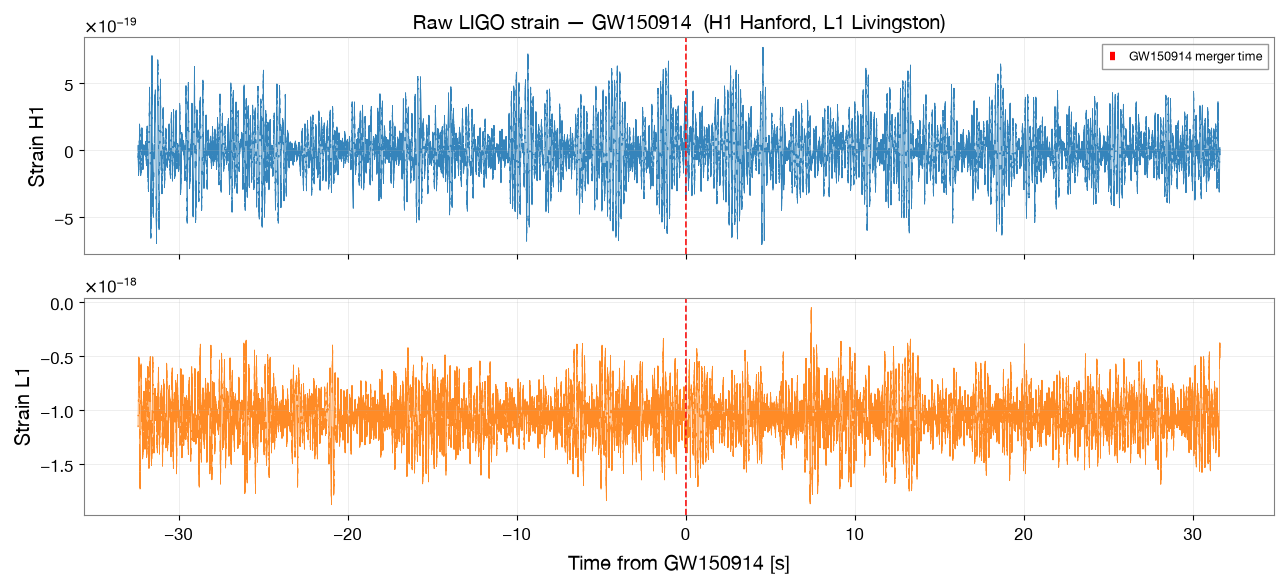

Observation: the gravitational-wave signal is invisible in the raw data.
The detector noise completely dominates.


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

axes[0].plot(t_h1, x_h1, lw=0.5, color=COLOR["H1"], alpha=0.9)
axes[0].axvline(0, ls="--", color="red", lw=1.2, label=f"{EVENT} merger time")
axes[0].set_ylabel("Strain H1")
axes[0].set_title(f"Raw LIGO strain — {EVENT}  (H1 Hanford, L1 Livingston)")
axes[0].legend(fontsize=9)
axes[0].yaxis.get_major_formatter().set_useOffset(False)

axes[1].plot(t_l1, x_l1, lw=0.5, color=COLOR["L1"], alpha=0.9)
axes[1].axvline(0, ls="--", color="red", lw=1.2)
axes[1].set_ylabel("Strain L1")
axes[1].set_xlabel(f"Time from {EVENT} [s]")
axes[1].yaxis.get_major_formatter().set_useOffset(False)

plt.tight_layout()
plt.show()

print("Observation: the gravitational-wave signal is invisible in the raw data.")
print("The detector noise completely dominates.")

## 3. Power Spectral Density (PSD) and sensitivity curve

The PSD describes how the noise is distributed in frequency. It is fundamental for two reasons:
- to understand the frequency bands in which the detector is sensitive;
- to build the correct whitening: dividing in the Fourier domain by $\sqrt{S_n(f)}$.

In the band [30, 1000] Hz LIGO reaches a sensitivity of $\sim 10^{-23}$ Hz$^{-1/2}$.
Below ~30 Hz seismic and Newtonian-gravity noise dominate; below ~10 Hz the detector is essentially blind.

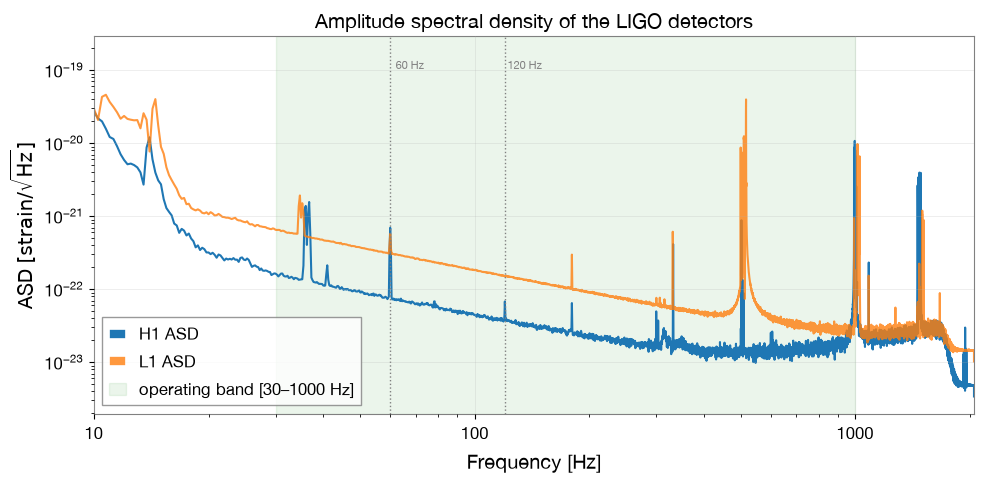

In [5]:
# PSD estimate with Welch's method (average of periodograms over overlapping windows)
# Use only the OFF-signal segment: avoid the ±1 s window around the event

mask_off = np.abs(t_h1) > 5.0   # segment far from the merger

nperseg_psd = int(4 * fs)        # 4 s windows → spectral resolution 0.25 Hz

f_psd_h1, psd_h1 = welch(x_h1[mask_off], fs=fs, nperseg=nperseg_psd, window="hann")
f_psd_l1, psd_l1 = welch(x_l1[mask_off], fs=fs, nperseg=nperseg_psd, window="hann")

fig, ax = plt.subplots(figsize=(10, 5))

ax.loglog(f_psd_h1, np.sqrt(psd_h1), color=COLOR["H1"], lw=1.5, label="H1 ASD")
ax.loglog(f_psd_l1, np.sqrt(psd_l1), color=COLOR["L1"], lw=1.5, label="L1 ASD", alpha=0.8)

# Highlight the main operating band
ax.axvspan(30, 1000, alpha=0.08, color="green", label="operating band [30–1000 Hz]")

ax.set_xlim(10, fs/2)
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel(r"ASD $[\mathrm{strain}/\sqrt{\mathrm{Hz}}]$")
ax.set_title("Amplitude spectral density of the LIGO detectors")
ax.legend()

# Annotations
ax.axvline(60,  ls=":", color="gray", lw=1)
ax.text(62,  ax.get_ylim()[1]*0.5, "60 Hz",  fontsize=8, color="gray", va="top")
ax.axvline(120, ls=":", color="gray", lw=1)
ax.text(122, ax.get_ylim()[1]*0.5, "120 Hz", fontsize=8, color="gray", va="top")

plt.tight_layout()
plt.show()

## 4. Preprocessing: whitening and band-pass

### Whitening
Whitening "flattens" the PSD: it divides the signal in the Fourier domain by $\sqrt{S_n(f)}$.
After whitening the noise has uniform variance over the whole band — the prerequisite for using energy statistics as detection statistics.

$$\tilde{d}_w(f) = \frac{\tilde{d}(f)}{\sqrt{S_n(f)}}$$

### Band-pass
Butterworth filter [30–500 Hz] to remove the low frequencies (seismic noise) and the high frequencies (where the detector is less sensitive).

In [6]:
def psd_whiten(x, fs, nperseg=None):
    """
    Whitening by dividing by the ASD estimated with Welch.
    Returns the whitened signal in the time domain.
    """
    if nperseg is None:
        nperseg = int(4 * fs)
    N = len(x)
    freqs, psd = welch(x, fs=fs, nperseg=nperseg, window="hann")
    # Interpolate the ASD on the full frequency axis
    full_f   = np.fft.rfftfreq(N, d=1/fs)
    asd_interp = np.interp(full_f, freqs, np.sqrt(psd))
    asd_interp[0] = 1.0   # avoid division by zero at f=0
    # Division in the frequency domain
    X_white = np.fft.rfft(x) / (asd_interp * np.sqrt(fs / 2))
    x_white = np.fft.irfft(X_white, n=N)
    return x_white


def bandpass(x, fs, low=30.0, high=500.0, order=4):
    """Butterworth bandpass."""
    nyq  = 0.5 * fs
    b, a = butter(order, [low / nyq, high / nyq], btype="band")
    return filtfilt(b, a, x)


# Apply whitening + band-pass to H1
x_h1_w  = psd_whiten(x_h1, fs)
x_h1_bp = bandpass(x_h1_w, fs, low=30, high=500)

x_l1_w  = psd_whiten(x_l1, fs)
x_l1_bp = bandpass(x_l1_w, fs, low=30, high=500)

print("Whitening + band-pass applied.")
print(f"H1 whitened — std = {x_h1_bp.std():.3f}")
print(f"L1 whitened — std = {x_l1_bp.std():.3f}")

Whitening + band-pass applied.
H1 whitened — std = 0.677
L1 whitened — std = 21.888


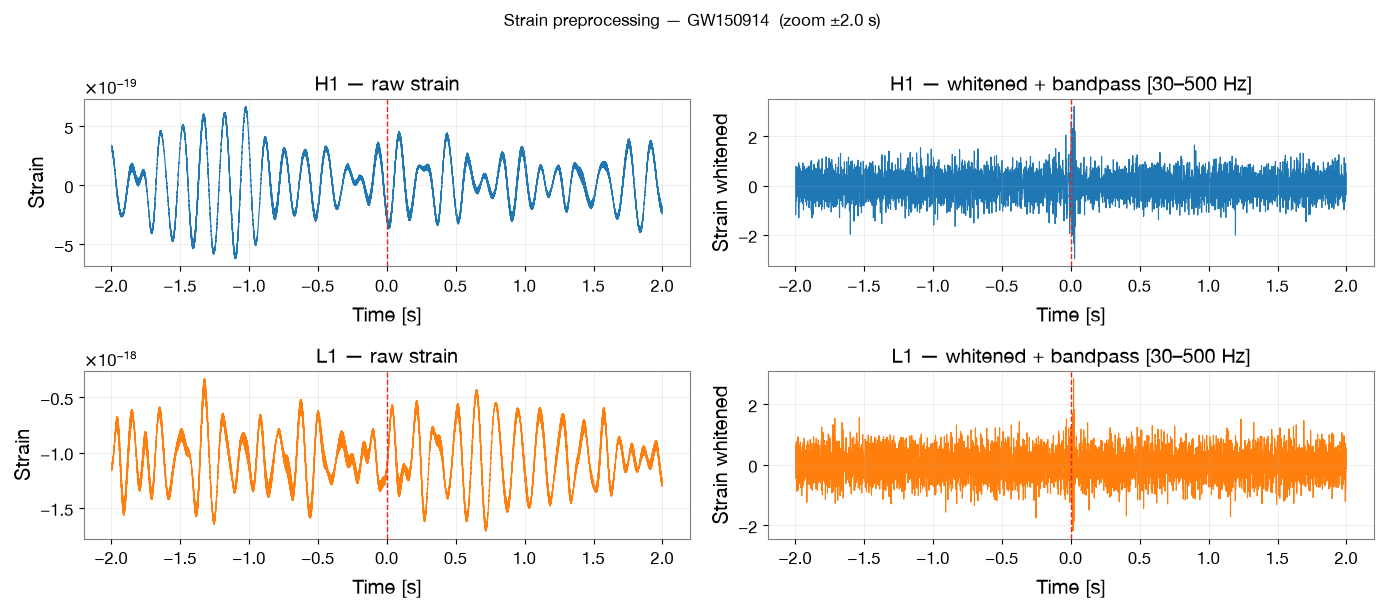

Note: the GW150914 signal becomes visible in H1 and L1 after whitening.


In [7]:
# Comparison: raw vs preprocessed strain, ±2 s window
zoom = 2.0

fig, axes = plt.subplots(2, 2, figsize=(14, 6))

for ax, t_arr, x_raw, x_proc, label, color in zip(
    axes,
    [t_h1,      t_l1],
    [x_h1,      x_l1],
    [x_h1_bp,   x_l1_bp],
    ["H1",      "L1"],
    [COLOR["H1"], COLOR["L1"]],
):
    mask = np.abs(t_arr) < zoom

    ax[0].plot(t_arr[mask], x_raw[mask], lw=0.8, color=color)
    ax[0].axvline(0, ls="--", color="red", lw=1)
    ax[0].set_title(f"{label} — raw strain")
    ax[0].set_xlabel("Time [s]")
    ax[0].set_ylabel("Strain")

    ax[1].plot(t_arr[mask], x_proc[mask], lw=0.8, color=color)
    ax[1].axvline(0, ls="--", color="red", lw=1)
    ax[1].set_title(f"{label} — whitened + bandpass [30–500 Hz]")
    ax[1].set_xlabel("Time [s]")
    ax[1].set_ylabel("Strain whitened")

plt.suptitle(f"Strain preprocessing — {EVENT}  (zoom ±{zoom} s)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

print("Note: the GW150914 signal becomes visible in H1 and L1 after whitening.")

## 5. Time–frequency representation: spectrogram and Q-transform

The STFT spectrogram shows how the signal energy is distributed in the time–frequency plane.
The Q-transform (used internally by GWpy and by the real cWB) is more efficient for chirp signals because it adapts the time resolution to the instantaneous frequency.

Here we implement a simplified version of the Q-transform as a multi-resolution spectrogram.

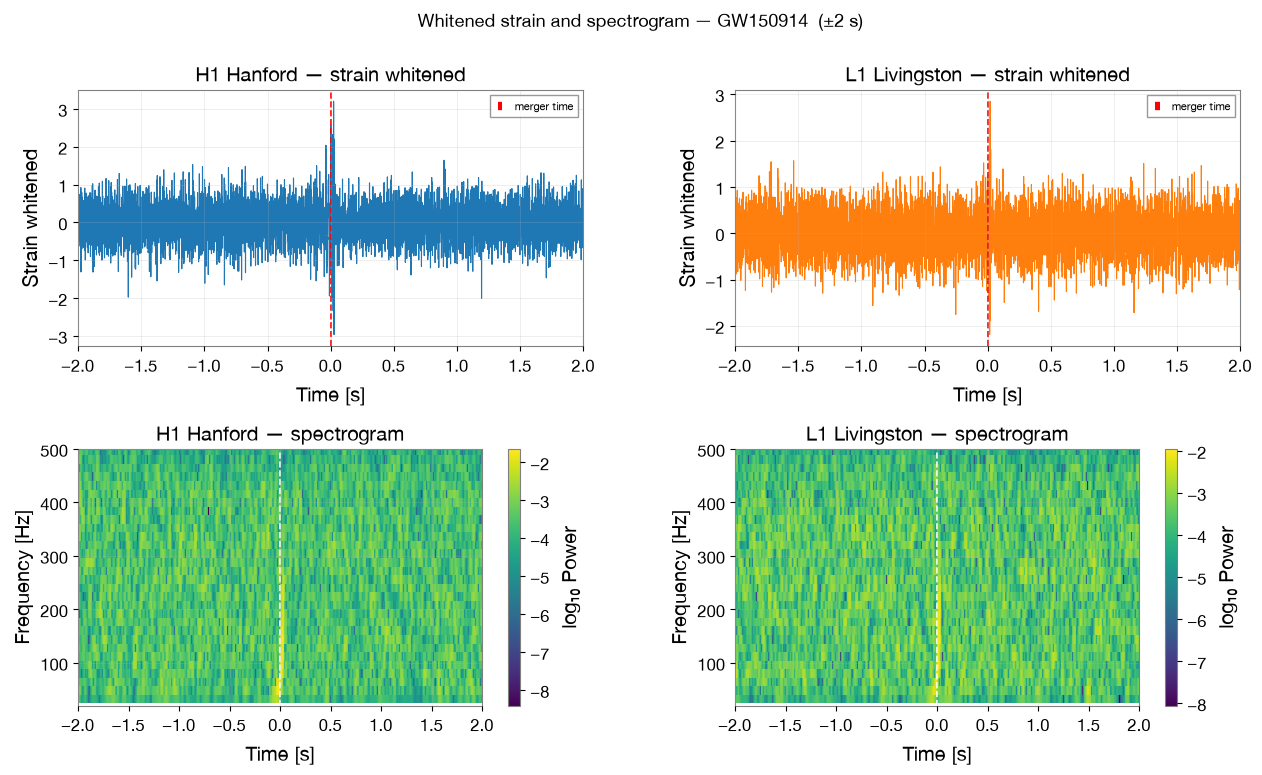

In [8]:
def compute_spectrogram(x, fs, nperseg=256, noverlap=224, f_min=20, f_max=600):
    """STFT spectrogram with frequency slicing."""
    f, t_spec, Sxx = spectrogram(x, fs=fs, nperseg=nperseg, noverlap=noverlap,
                                  window="hann", scaling="density")
    mask = (f >= f_min) & (f <= f_max)
    return f[mask], t_spec, Sxx[mask]


def plot_spectrogram(t_arr, x_proc, gps_ref, label, color, ax_time, ax_spec,
                     t_window=None, f_min=20, f_max=500):
    """Helper: strain and spectrogram side by side."""
    if t_window is None:
        t_window = (-2.0, 2.0)
    mask = (t_arr >= t_window[0]) & (t_arr <= t_window[1])

    ax_time.plot(t_arr[mask], x_proc[mask], lw=0.8, color=color)
    ax_time.axvline(0, ls="--", color="red", lw=1.2, label="merger time")
    ax_time.set_xlabel("Time [s]")
    ax_time.set_ylabel("Strain whitened")
    ax_time.set_title(f"{label} — strain whitened")
    ax_time.set_xlim(t_window)
    ax_time.legend(fontsize=8)

    f_s, t_s, Sxx = compute_spectrogram(x_proc, fs, f_min=f_min, f_max=f_max)
    t_s_rel = t_s + t_arr[0]
    mask_t = (t_s_rel >= t_window[0]) & (t_s_rel <= t_window[1])

    mesh = ax_spec.pcolormesh(
        t_s_rel[mask_t], f_s,
        np.log10(Sxx[:, mask_t] + 1e-30),
        shading="auto", cmap="viridis"
    )
    ax_spec.axvline(0, ls="--", color="white", lw=1.2)
    ax_spec.set_xlabel("Time [s]")
    ax_spec.set_ylabel("Frequency [Hz]")
    ax_spec.set_title(f"{label} — spectrogram")
    ax_spec.set_xlim(t_window)
    ax_spec.set_ylim(f_min, f_max)
    return mesh


fig = plt.figure(figsize=(15, 8))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.3)

ax_h1_t = fig.add_subplot(gs[0, 0])
ax_h1_s = fig.add_subplot(gs[1, 0])
ax_l1_t = fig.add_subplot(gs[0, 1])
ax_l1_s = fig.add_subplot(gs[1, 1])

mesh_h1 = plot_spectrogram(t_h1, x_h1_bp, gps, "H1 Hanford",   COLOR["H1"], ax_h1_t, ax_h1_s)
mesh_l1 = plot_spectrogram(t_l1, x_l1_bp, gps, "L1 Livingston", COLOR["L1"], ax_l1_t, ax_l1_s)

fig.colorbar(mesh_h1, ax=ax_h1_s, label="log₁₀ Power")
fig.colorbar(mesh_l1, ax=ax_l1_s, label="log₁₀ Power")

fig.suptitle(f"Whitened strain and spectrogram — {EVENT}  (±2 s)", fontsize=13)
plt.show()

### Simplified Q-transform

The Q-transform uses a family of Gaussian windows in the frequency domain, with width proportional to the central frequency (constant bandwidth on a logarithmic scale). The parameter $Q$ controls the time/frequency resolution trade-off:

$$\Delta t \cdot \Delta f \approx \frac{Q}{4\pi f_0}$$

Here we implement a didactic version: a multi-$Q$ spectrogram with variable overlap.

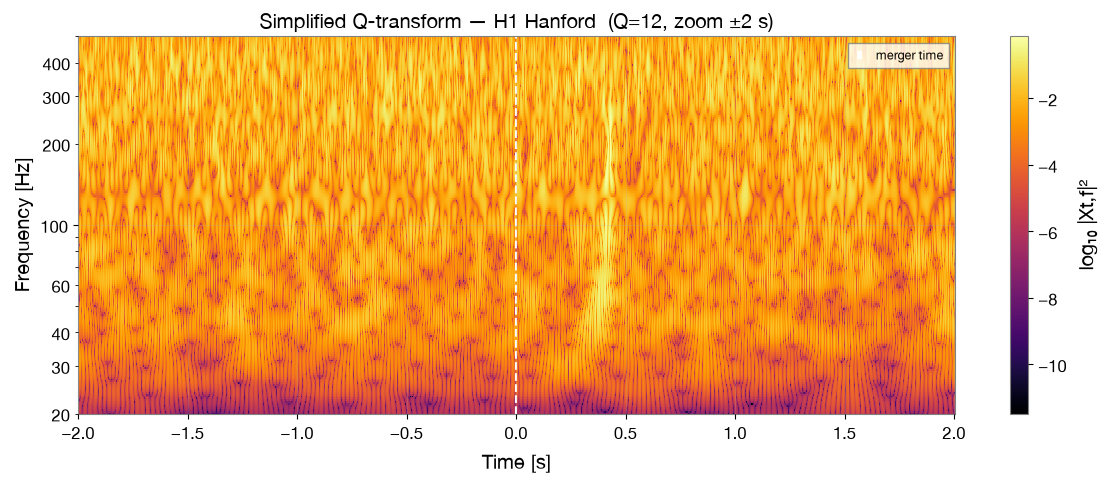

In [9]:
def q_transform_simple(x, fs, Q=12, f_min=20, f_max=500, n_freqs=200, t_window=(-2.0, 2.0)):
    """
    Simplified Q-transform: computes |X(t, f)|^2 with Gaussian windows
    in the Fourier domain, for each central frequency f0 on a log scale.
    """
    N = len(x)
    X = np.fft.rfft(x)
    freqs_fft = np.fft.rfftfreq(N, d=1/fs)

    # Central frequencies on a logarithmic scale
    f_centers = np.logspace(np.log10(f_min), np.log10(f_max), n_freqs)

    # Number of samples of the output time window
    t_out = np.linspace(t_window[0], t_window[1], int((t_window[1] - t_window[0]) * fs / 16))
    map_qt = np.zeros((len(f_centers), len(t_out)))

    for i, f0 in enumerate(f_centers):
        sigma_f = f0 / Q        # width of the Gaussian in frequency
        # Gaussian window in frequency centred on f0
        window  = np.exp(-0.5 * ((freqs_fft - f0) / sigma_f)**2)
        window += np.exp(-0.5 * ((freqs_fft + f0) / sigma_f)**2)  # negative-frequency part
        # Filtering and inverse transform
        x_filtered = np.fft.irfft(X * window, n=N)
        # Envelope amplitude
        t_full = np.arange(N) / fs - N / (2 * fs)
        map_qt[i, :] = np.interp(t_out, t_full, np.abs(x_filtered)**2)

    return t_out, f_centers, map_qt


# Compute the Q-transform for H1
t_qt, f_qt, Sqt = q_transform_simple(x_h1_bp, fs, Q=12, t_window=(-2, 2))

fig, ax = plt.subplots(figsize=(12, 5))
mesh = ax.pcolormesh(t_qt, f_qt, np.log10(Sqt + 1e-30), shading="auto", cmap="inferno")
ax.axvline(0, ls="--", color="white", lw=1.5, label="merger time")
ax.set_yscale("log")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Frequency [Hz]")
ax.set_title(f"Simplified Q-transform — H1 Hanford  (Q=12, zoom ±2 s)")
ax.set_ylim(20, 500)
ax.legend(fontsize=9)
fig.colorbar(mesh, ax=ax, label="log₁₀ |Xt,f|²")
plt.tight_layout()
plt.show()

## 6. Simulated burst morphologies

The project uses three morphologies as signals to be injected into real noise:

| Morphology | Formula | Key parameters |
|---|---|---|
| Sine-Gaussian | $h(t) = A\,e^{-(t-t_0)^2/2\sigma^2}\sin(2\pi f_0 t + \phi)$ | $A, t_0, f_0, Q$ |
| Gaussian pulse | $h(t) = A\,e^{-(t-t_0)^2/2\sigma^2}$ | $A, t_0, \sigma$ |
| Linear chirp | $h(t) = A\,e^{-(t-t_0)^2/2\sigma^2}\sin\!\left(2\pi(f_0 + \tfrac{1}{2}\dot{f}\,t)\,t\right)$ | $A, f_0, \dot{f}, \sigma$ |

The parameter $Q$ of the sine-Gaussian controls the duration relative to the frequency: $\sigma = Q/(2\pi f_0)$.
(Notebook `02` uses the cosine-phase convention and the exact analytic Fourier transforms.)

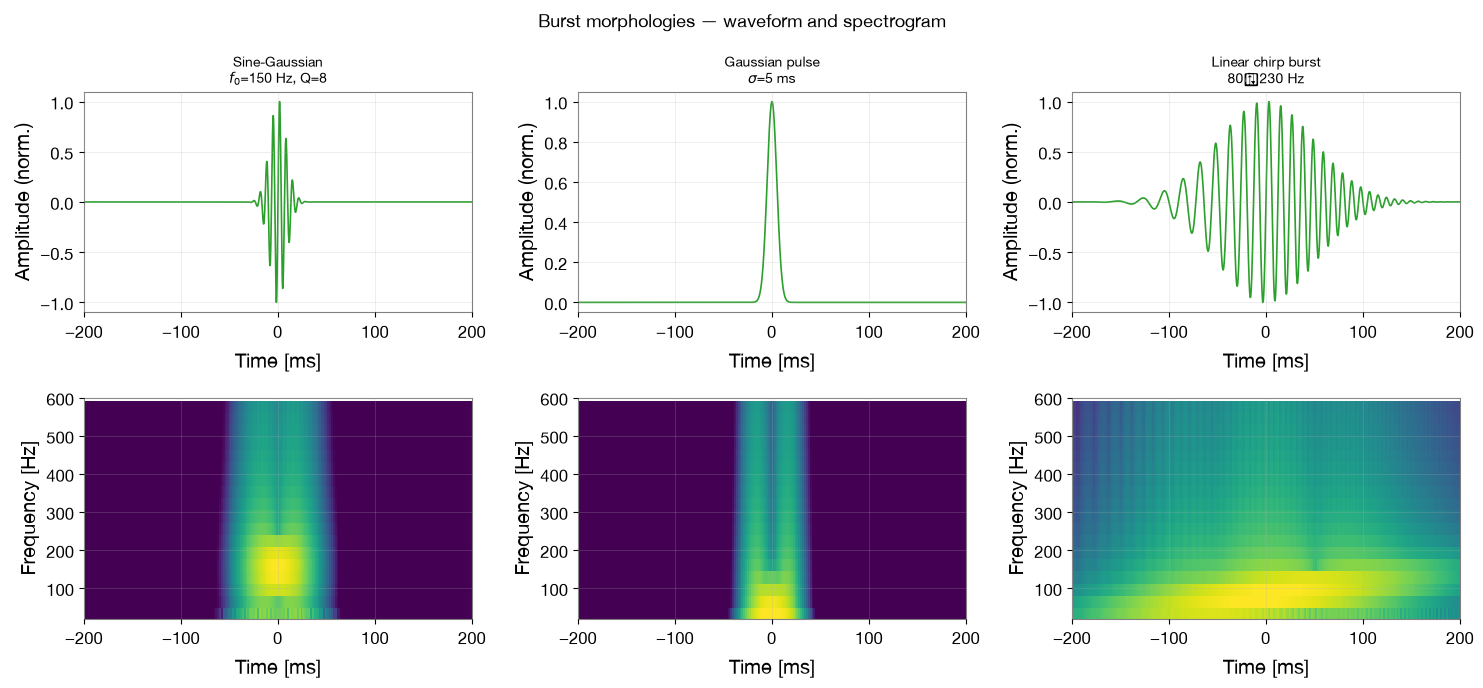

In [10]:
# ── Burst functions ──────────────────────────────────────────────────────────

def sine_gaussian(t, t0=0.0, f0=150.0, Q=8.0, amplitude=1.0, phase=0.0):
    """Sine-Gaussian burst: Gaussian envelope × sinusoidal carrier."""
    sigma = Q / (2 * np.pi * f0)
    tau   = t - t0
    return amplitude * np.exp(-0.5 * (tau / sigma)**2) * np.sin(2 * np.pi * f0 * tau + phase)


def gaussian_pulse(t, t0=0.0, sigma=0.01, amplitude=1.0):
    """Pure Gaussian burst: energy concentrated in time, broad spectrum."""
    return amplitude * np.exp(-0.5 * ((t - t0) / sigma)**2)


def linear_chirp_burst(t, t0=0.0, f0=80.0, f_dot=300.0, sigma=0.05, amplitude=1.0):
    """Rising-frequency chirp with a Gaussian envelope."""
    tau   = t - t0
    f_inst = f0 + f_dot * tau
    phase  = 2 * np.pi * (f0 * tau + 0.5 * f_dot * tau**2)
    return amplitude * np.exp(-0.5 * (tau / sigma)**2) * np.sin(phase)


# ── Morphology visualisation ─────────────────────────────────────────────────

t_burst = np.linspace(-0.3, 0.3, int(0.6 * fs))

bursts = {
    "Sine-Gaussian\n$f_0$=150 Hz, Q=8": sine_gaussian(t_burst, f0=150, Q=8),
    "Gaussian pulse\n$\sigma$=5 ms":     gaussian_pulse(t_burst, sigma=0.005),
    "Linear chirp burst\n80→230 Hz": linear_chirp_burst(t_burst, f0=80, f_dot=300, sigma=0.05),
}

fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for col, (name, burst) in enumerate(bursts.items()):
    # Normalisation for display
    burst_n = burst / (np.max(np.abs(burst)) + 1e-12)

    axes[0, col].plot(t_burst * 1e3, burst_n, lw=1.2, color=COLOR["burst"])
    axes[0, col].set_title(name, fontsize=10)
    axes[0, col].set_xlabel("Time [ms]")
    axes[0, col].set_ylabel("Amplitude (norm.)")
    axes[0, col].set_xlim(-200, 200)

    # Spectrogram
    f_b, t_b, Sxx_b = spectrogram(burst_n, fs=fs, nperseg=128, noverlap=120, window="hann")
    mask_f = (f_b >= 20) & (f_b <= 600)
    axes[1, col].pcolormesh(
        (t_b + t_burst[0]) * 1e3, f_b[mask_f],
        np.log10(Sxx_b[mask_f] + 1e-20),
        shading="auto", cmap="viridis"
    )
    axes[1, col].set_xlabel("Time [ms]")
    axes[1, col].set_ylabel("Frequency [Hz]")
    axes[1, col].set_xlim(-200, 200)
    axes[1, col].set_ylim(20, 600)

plt.suptitle("Burst morphologies — waveform and spectrogram", fontsize=13)
plt.tight_layout()
plt.show()

## 7. Injection into real noise

We build the core of the supervised dataset: take a window of real noise from H1 and inject a sine-Gaussian burst with controlled SNR.

The analytic SNR of an injection is defined as:

$$\mathrm{SNR}^2 = 4 \int_0^\infty \frac{|\tilde{h}(f)|^2}{S_n(f)}\,df$$

In the whitened version (PSD ≈ 1 over the whole band) this reduces to:

$$\mathrm{SNR}_{\mathrm{whitened}} \approx \left\| h_w(t) \right\|_2 = \sqrt{\sum_i h_w(t_i)^2 \cdot \Delta t}$$

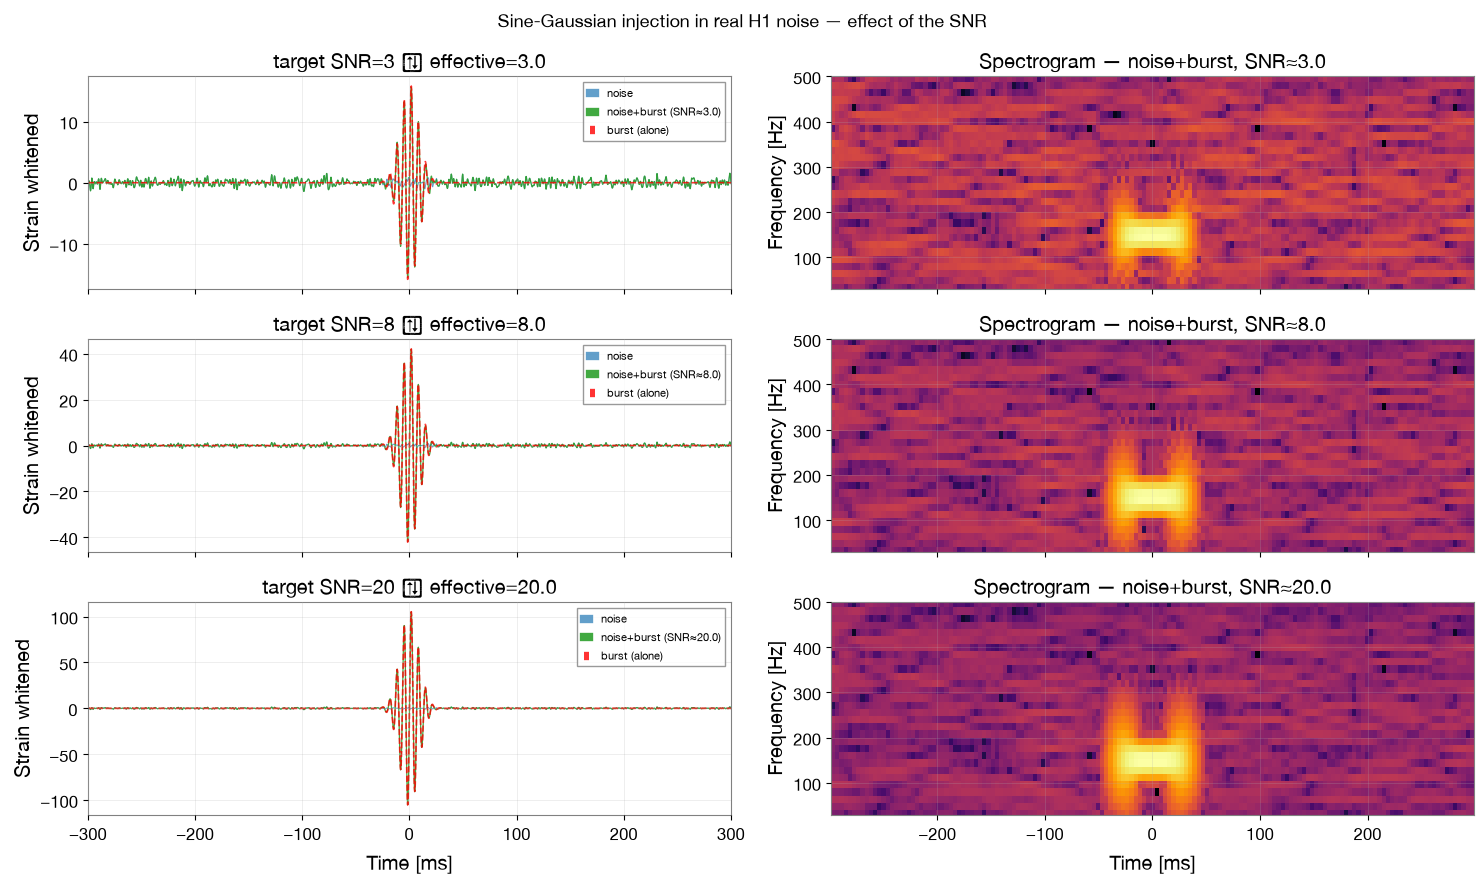

In [11]:
def inject_burst(noise_seg, t_seg, burst_waveform, target_snr=10.0, fs=4096):
    """
    Inject burst_waveform into noise_seg scaling the amplitude to target_snr.
    SNR estimated as the L2 norm of the whitened signal divided by the noise std.
    """
    noise_std  = np.std(noise_seg)
    burst_norm = np.sqrt(np.sum(burst_waveform**2) / fs)  # normalised norm
    scale      = target_snr * noise_std / (burst_norm + 1e-30)
    burst_scaled = burst_waveform * scale
    signal_seg   = noise_seg + burst_scaled
    # effective SNR
    snr_effective = np.sqrt(np.sum(burst_scaled**2) / fs) / noise_std
    return signal_seg, burst_scaled, snr_effective


# Select a 2 s window of real H1 noise
seg_dur  = 2.0
n_seg    = int(seg_dur * fs)
# Take a window far from the merger (t ~ -10 s)
t_inj_center = -10.0
idx_c    = np.argmin(np.abs(t_h1 - t_inj_center))
idx_start = max(0, idx_c - n_seg // 2)
idx_end   = idx_start + n_seg

noise_seg = x_h1_bp[idx_start:idx_end].copy()
t_seg     = t_h1[idx_start:idx_end]
t_seg_rel = t_seg - t_seg[n_seg // 2]  # centred relative time

# Build the burst to inject
burst_raw = sine_gaussian(t_seg_rel, t0=0.0, f0=150.0, Q=8.0, amplitude=1.0)

# Injection with different target SNRs
snr_list = [3, 8, 20]

fig, axes = plt.subplots(len(snr_list), 2, figsize=(15, 9), sharex="col")

for row, snr_target in enumerate(snr_list):
    sig_seg, burst_scaled, snr_eff = inject_burst(noise_seg, t_seg_rel, burst_raw, target_snr=snr_target, fs=fs)

    t_ms = t_seg_rel * 1e3
    zoom_ms = 300

    axes[row, 0].plot(t_ms, noise_seg, lw=0.7, alpha=0.7, color=COLOR["H1"],    label="noise")
    axes[row, 0].plot(t_ms, sig_seg,   lw=0.9, alpha=0.9, color=COLOR["burst"], label=f"noise+burst (SNR≈{snr_eff:.1f})")
    axes[row, 0].plot(t_ms, burst_scaled, lw=1.2, ls="--", color="red", alpha=0.8, label="burst (alone)")
    axes[row, 0].set_xlim(-zoom_ms, zoom_ms)
    axes[row, 0].set_ylabel("Strain whitened")
    axes[row, 0].legend(fontsize=8)
    axes[row, 0].set_title(f"target SNR={snr_target} → effective={snr_eff:.1f}")

    # Spectrogram of the injected segment
    f_s, t_s, Sxx = spectrogram(sig_seg, fs=fs, nperseg=256, noverlap=240)
    t_s_ms = (t_s - seg_dur / 2) * 1e3
    mask_f = (f_s >= 30) & (f_s <= 500)
    mask_t = np.abs(t_s_ms) < zoom_ms
    axes[row, 1].pcolormesh(
        t_s_ms[mask_t], f_s[mask_f],
        np.log10(Sxx[mask_f][:, mask_t] + 1e-25),
        shading="auto", cmap="inferno"
    )
    axes[row, 1].set_ylabel("Frequency [Hz]")
    axes[row, 1].set_ylim(30, 500)
    axes[row, 1].set_title(f"Spectrogram — noise+burst, SNR≈{snr_eff:.1f}")

axes[-1, 0].set_xlabel("Time [ms]")
axes[-1, 1].set_xlabel("Time [ms]")

plt.suptitle("Sine-Gaussian injection in real H1 noise — effect of the SNR", fontsize=13)
plt.tight_layout()
plt.show()

## 8. SNR and signal visibility

Here we systematically explore how the SNR controls the visibility of the burst in the time–frequency plane. This is a prerequisite to understand the performance of any detection statistic.

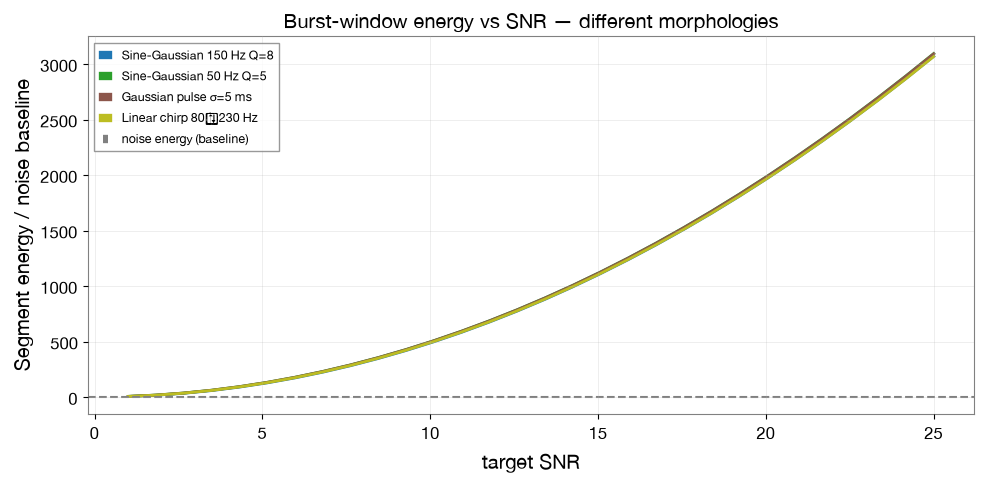

Note: this is the kind of statistic used as the frequentist baseline in the next stage (notebook 03).


In [12]:
rng = np.random.default_rng(123)

# SNR scan over different injection morphologies
snr_scan = np.linspace(1, 25, 30)

morphologies = {
    "Sine-Gaussian 150 Hz Q=8":  lambda t: sine_gaussian(t, f0=150, Q=8),
    "Sine-Gaussian 50 Hz Q=5":   lambda t: sine_gaussian(t, f0=50,  Q=5),
    "Gaussian pulse σ=5 ms":     lambda t: gaussian_pulse(t, sigma=0.005),
    "Linear chirp 80→230 Hz":    lambda t: linear_chirp_burst(t, f0=80, f_dot=300, sigma=0.05),
}

# For every morphology and target SNR: energy of the window around the burst
# as a proxy of detectability

results = {name: [] for name in morphologies}
results_noise = {name: [] for name in morphologies}

for name, burst_fn in morphologies.items():
    burst_wf = burst_fn(t_seg_rel)
    for snr_t in snr_scan:
        sig_seg, bs, snr_eff = inject_burst(noise_seg, t_seg_rel, burst_wf, target_snr=snr_t, fs=fs)
        # Energy in the burst time window (±100 ms)
        t_mask = np.abs(t_seg_rel) < 0.1
        energy_sig   = np.sum(sig_seg[t_mask]**2) / np.sum(t_mask)
        energy_noise = np.sum(noise_seg[t_mask]**2) / np.sum(t_mask)
        results[name].append(energy_sig)
        results_noise[name].append(energy_noise)

fig, ax = plt.subplots(figsize=(10, 5))

colors_morph = plt.cm.tab10(np.linspace(0, 0.8, len(morphologies)))
for (name, energies), color in zip(results.items(), colors_morph):
    ratio = np.array(energies) / np.mean(list(results_noise.values())[0])
    ax.plot(snr_scan, ratio, lw=2, label=name, color=color)

ax.axhline(1.0, ls="--", color="gray", label="noise energy (baseline)")
ax.set_xlabel("target SNR")
ax.set_ylabel("Segment energy / noise baseline")
ax.set_title("Burst-window energy vs SNR — different morphologies")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print("Note: this is the kind of statistic used as the frequentist baseline in the next stage (notebook 03).")

## 9. Summary and next steps

This notebook covered the structure of the raw GWOSC data and the preprocessing operations needed to build any later analysis.

### What we saw

| Block | Main output |
|---|---|
| GWOSC download | H1/L1 strain around GW150914 |
| PSD + ASD | Detector sensitivity curve, noise lines at 60/120 Hz |
| Whitening + band-pass | Standardised strain over the band [30–500 Hz] |
| Spectrogram + Q-transform | Time–frequency plane, visualisation of the GW150914 chirp |
| Burst morphologies | Sine-Gaussian, Gaussian pulse, linear chirp — waveforms and TF maps |
| Injection + SNR scan | Effect of the SNR on the visibility of the burst in real noise |

### Where the project goes next

1. **`01` data and noise validation** — noise-only segments from O1 (far from known events), whitening, Gaussianity and stationarity tests
2. **`02` waveforms and injections** — exact analytic waveforms, analytic optimal SNR, validated injection chain
3. **`03` frequentist analysis** — matched-filter bank, thresholds at fixed FAP, ROC, MLE, toy MC, systematics
4. **`04` Bayesian analysis** — posterior of the burst parameters, Bayes factors, calibration
5. **`05` ML detectors** — classifiers, CNN, autoencoder, calibration and uncertainty, comparison with the frequentist statistics